In [5]:
import utils
import numpy as np
import matplotlib.pyplot as plt

In [85]:
def get_unchecked_moore_neighbors(im: np.ndarray, row: int, col:int, seen_pixels: np.ndarray):
    (h, w) = im.shape
    neighbors = []
    for i in [-1, 0, 1]:
        for j in [-1, 0, 1]:
            if (i, j) != (0, 0):
                if ((row+i) in range(h)) and ((col+j) in range(w)):
                    if (not seen_pixels[row+i][col+j]):
                        neighbors.append((row+i, col+j))
    return neighbors

def region_growing(im: np.ndarray, seed_points: list, T: int) -> np.ndarray:
    """
        A region growing algorithm that segments an image into 1 or 0 (True or False).
        Finds candidate pixels with a Moore-neighborhood (8-connectedness). 
        Uses pixel intensity thresholding with the threshold T as the homogeneity criteria.
        The function takes in a grayscale image and outputs a boolean image

        args:
            im: np.ndarray of shape (H, W) in the range [0, 255] (dtype=np.uint8)
            seed_points: list of list containing seed points (row, col). Ex:
                [[row1, col1], [row2, col2], ...]
            T: integer value defining the threshold to used for the homogeneity criteria.
        return:
            (np.ndarray) of shape (H, W). dtype=bool
    """
    ### START YOUR CODE HERE ### (You can change anything inside this block)
    # You can also define other helper functions

    segmented = np.zeros_like(im).astype(bool)
    seen_pixels = np.zeros_like(im).astype(bool)
    im = im.astype(float)
    for row, col in seed_points:
        segmented[row, col] = True
        pixels_to_check = get_unchecked_moore_neighbors(im, row, col, seen_pixels)
        while pixels_to_check != []:
            (x, y) = pixels_to_check.pop()
            seen_pixels[x][y] = True
            if np.abs(im[x][y] - im[row][col]) <= T:
                segmented[x, y] = True
                neighbors = get_unchecked_moore_neighbors(im, x, y, seen_pixels)
                for neighbor in neighbors:
                    if not (neighbor in pixels_to_check):
                        pixels_to_check.append(neighbor)


    return segmented
    ### END YOUR CODE HERE ### 

Reading image: images/defective-weld.png
Saving image to: image_processed/defective-weld-segmented.png


/home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/.venv/lib/python3.10/site-packages/skimage/_shared/utils.py:328: UserWarning: /home/clem/Bureau/Visual_Computing_Fundamentals/Part2_Image_Processing/Assignments/TDT4195-StarterCode-2025/Assignment 3/image_processed/defective-weld-segmented.png is a low contrast image
  return func(*args, **kwargs)


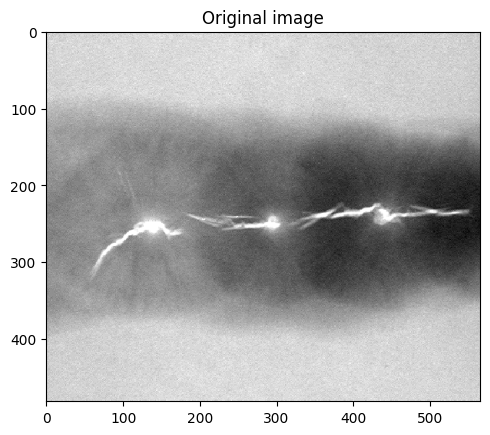

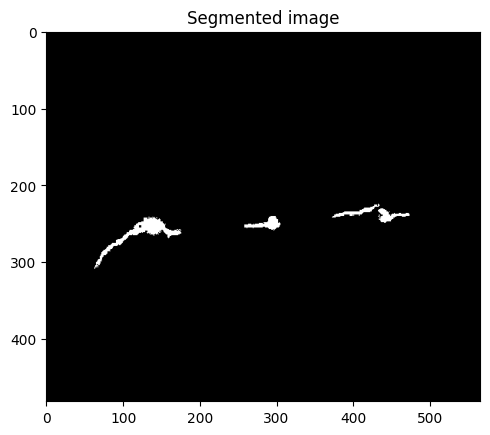

In [86]:
if __name__ == "__main__":
    # DO NOT CHANGE
    im = utils.read_image("defective-weld.png")

    seed_points = [ # (row, column)
        [254, 138], # Seed point 1
        [253, 296], # Seed point 2
        [233, 436], # Seed point 3
        [232, 417], # Seed point 4
    ]
    intensity_threshold = 50
    segmented_image = region_growing(im, seed_points, intensity_threshold)

    assert im.shape == segmented_image.shape, "Expected image shape ({}) to be same as thresholded image shape ({})".format(
        im.shape, segmented_image.shape)
    assert segmented_image.dtype == bool, "Expected thresholded image dtype to be bool. Was: {}".format(
            segmented_image.dtype)

    segmented_image = utils.to_uint8(segmented_image)
    utils.save_im("defective-weld-segmented.png", segmented_image)

    fig, ax = plt.subplots(1,1)
    plt.imshow(im, cmap="gray")
    plt.title("Original image")

    fig, ax = plt.subplots(1,1)
    plt.imshow(segmented_image, cmap="gray")
    plt.title("Segmented image")
